# Ejercicio 2 — Memoria asociativa con redes de Hopfield

## Índice

Siguiendo la recomendación del enunciado, primero se prueba la red con letras (2.2) y después se pasa a los códigos QR (2.1).

**2.2 Letras de 5×5**

1. [Modelo de Hopfield](#1.-Modelo-de-Hopfield)
2. [Elección de las letras y ortogonalidad](#2.-Elección-de-las-letras-y-ortogonalidad)
3. [Capacidad de almacenamiento](#3.-Capacidad-de-almacenamiento)
4. [Recuperación con ruido](#4.-Recuperación-con-ruido)
5. [Estados espurios](#5.-Estados-espurios)

**2.1 Recuperación de códigos QR deteriorados**

6. [Los códigos QR como patrones](#6.-Los-códigos-QR-como-patrones)
7. [Hebb falla: regla de la pseudoinversa](#7.-Hebb-falla:-regla-de-la-pseudoinversa)
8. [Deterioro de los códigos y lectura](#8.-Deterioro-de-los-códigos-y-lectura)
9. [Iteraciones y energía](#9.-Iteraciones-y-energía)
10. [Limitaciones del caso de uso](#10.-Limitaciones-del-caso-de-uso)
11. [Conclusiones](#11.-Conclusiones)

## 1. Modelo de Hopfield

Cada patrón es un vector $\xi \in \{-1, 1\}^N$ (un píxel por neurona: $+1$ negro, $-1$ blanco). La red guarda $M$ patrones en una matriz de pesos simétrica $W$ con diagonal nula y, ante una consulta, actualiza **una neurona por vez** en orden aleatorio:

$$s_i \leftarrow \operatorname{sign}(h_i), \qquad h_i = \sum_j W_{ij}\, s_j$$

hasta que ninguna cambia (punto fijo). Con $W$ simétrica y diagonal nula, cada cambio baja la **energía** $E(s) = -\tfrac12\, s^\top W s$ en $2|h_i|$, así que la red siempre converge a un mínimo local. Los patrones almacenados deberían ser esos mínimos.

- **Regla de Hebb:** $W = \frac1N \sum_\mu \xi^\mu \xi^{\mu\top}$. El campo de una neurona de un patrón almacenado es su propio valor más un **ruido cruzado** proporcional al solapamiento con los demás patrones. Funciona si los patrones son casi ortogonales.
- **Regla de la pseudoinversa:** $W = P^\top (P P^\top)^{-1} P$, la proyección sobre el espacio que generan los patrones. Cada patrón es punto fijo aunque estén correlacionados, siempre que sean linealmente independientes.

El código está en módulos: `hopfield.py` (red, puntos fijos y experimentos de recuperación), `letters.py` (alfabeto y elección de letras), `noise.py` (ruido y daños), `qr.py` (carga y lector de QR con `zxing-cpp`) y `plots.py`.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Permite ejecutar el notebook tanto desde la raíz del repositorio como desde TP4.
cwd = Path.cwd()
tp4_dir = cwd / "TP4" if (cwd / "TP4" / "hopfield.py").exists() else cwd
if str(tp4_dir) not in sys.path:
    sys.path.insert(0, str(tp4_dir))

import letters
import noise
import plots
import qr
from hopfield import Hopfield, fixed_points, identify, mixture, overlaps, recovery

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plots.set_style()

## 2. Elección de las letras y ortogonalidad

Se arma un alfabeto completo de 5×5 ($N = 25$); la J es la del enunciado. Con Hebb, lo que decide si dos letras se confunden es $|\xi^u \cdot \xi^v| / N$: la red guarda cada patrón **y su inverso**, así que un solapamiento de $-0.7$ es tan malo como uno de $+0.7$. Se evalúan los 14 950 grupos de 4 letras y se elige el de **menor solapamiento máximo** entre pares (y, a igualdad, menor solapamiento medio).

Grupos de 4 letras evaluados: 14950
J, O, X, L queda en la posición 10478


,letras,máx |solapamiento|,medio |solapamiento|
0,"G, R, T, V",0.12,0.05
1,"O, R, T, V",0.12,0.05
2,"L, R, T, X",0.12,0.07
3,"G, R, V, Z",0.12,0.07
4,"M, O, R, Z",0.12,0.07
5,"A, F, P, R",0.84,0.71
6,"H, M, N, W",0.84,0.73


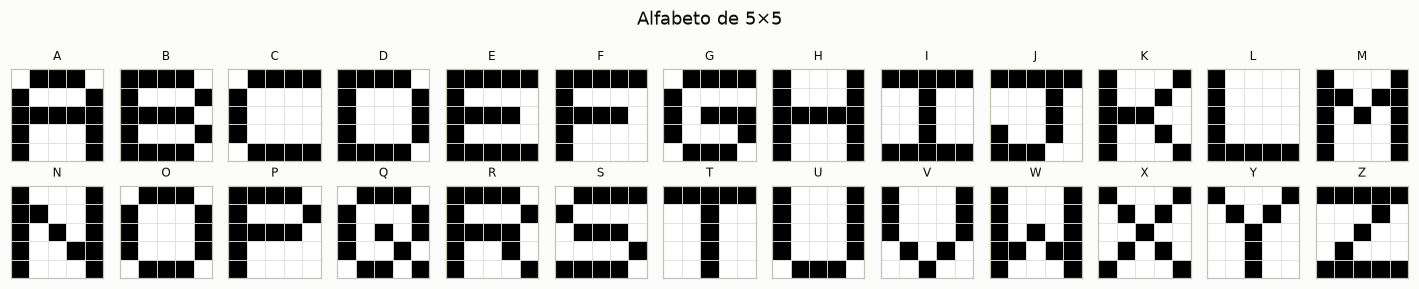

In [2]:
ranking = letters.most_orthogonal(4)
GROUP = list(ranking[0][2])
DRAFT_GROUP = ["J", "O", "X", "L"]
WORST_GROUP = list(ranking[-1][2])

summary = pd.DataFrame(
    [(", ".join(group), worst, mean) for worst, mean, group in ranking[:5] + ranking[-2:]],
    columns=["letras", "máx |solapamiento|", "medio |solapamiento|"],
)
position = next(i for i, (_, _, g) in enumerate(ranking) if set(g) == set(DRAFT_GROUP))
print(f"Grupos de 4 letras evaluados: {len(ranking)}")
print(f"J, O, X, L queda en la posición {position + 1}")
display(summary)
plots.plot_patterns([letters.LETTERS[c] for c in letters.LETTERS], list(letters.LETTERS), ncols=13,
                    suptitle="Alfabeto de 5×5", size=1.0)
plt.show()

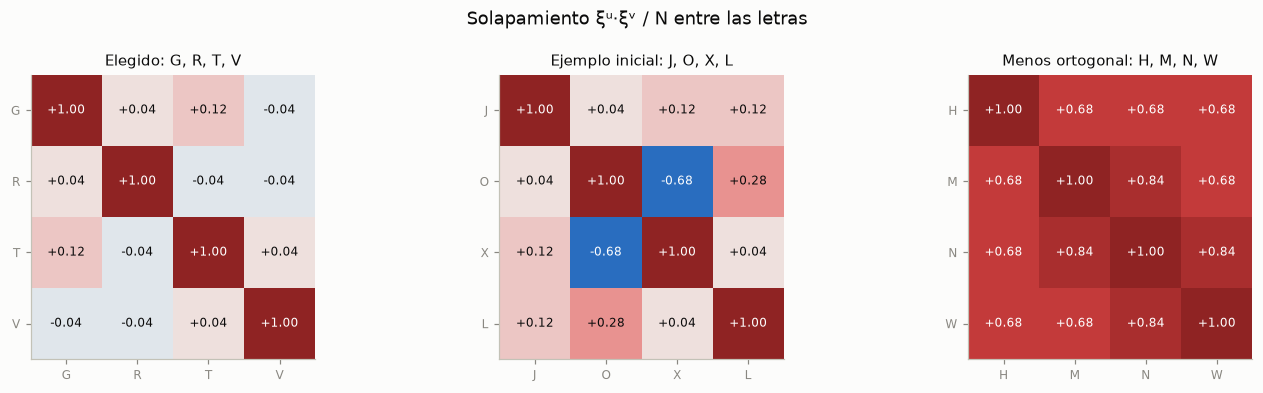

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (title, group) in zip(axes, {"Elegido": GROUP, "Ejemplo inicial": DRAFT_GROUP,
                                     "Menos ortogonal": WORST_GROUP}.items()):
    O = overlaps(letters.stack(group))
    ax.imshow(O, cmap=plots.DIVERGING, vmin=-1, vmax=1)
    for (r, c), value in np.ndenumerate(O):
        ax.text(c, r, f"{value:+.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(value) > 0.6 else plots.INK)
    ax.set_xticks(range(4), group)
    ax.set_yticks(range(4), group)
    ax.grid(False)
    ax.set_title(f"{title}: {', '.join(group)}")
fig.suptitle("Solapamiento ξᵘ·ξᵛ / N entre las letras", color=plots.INK)
fig.tight_layout()
plt.show()

Se eligen **G, R, T, V**: ningún par se solapa más de 0.12 (3 píxeles de diferencia neta sobre 25). Hay varios grupos empatados en 0.12 (O, R, T, V; L, R, T, X; …), así que el valor no depende de esta elección puntual.

Como contraste se usa un ejemplo inicial elegido a ojo, J, O, X, L (la J es la del enunciado). Queda en la posición 10 478 de 14 950: con este alfabeto la X es casi el **inverso** de la O (solapamiento $-0.68$). Como contraste, H, M, N, W comparten los dos trazos verticales y se solapan entre 0.68 y 0.84.

## 3. Capacidad de almacenamiento

Para patrones **al azar** e independientes, Hebb guarda unos $0.138\,N \approx 3.5$ patrones con $N = 25$, tolerando ~1 % de bits incorrectos. Si se exige recuperación perfecta, el límite baja a $N / (4 \ln N) \approx 1.9$. Las letras no son al azar (comparten bordes y trazos), así que se mide la capacidad real: para cada $M$ se toman 200 grupos de letras al azar y se cuenta qué fracción de letras queda como punto fijo y cuál se recupera desde una copia con 3 píxeles invertidos (12 %).

M,1,2,3,4,5,6,7,8,9,10
punto fijo,1.00,1.00,0.92,0.67,0.55,0.38,0.28,0.19,0.16,0.12
recuperada con ruido,1.00,1.00,0.86,0.59,0.43,0.28,0.18,0.13,0.11,0.08


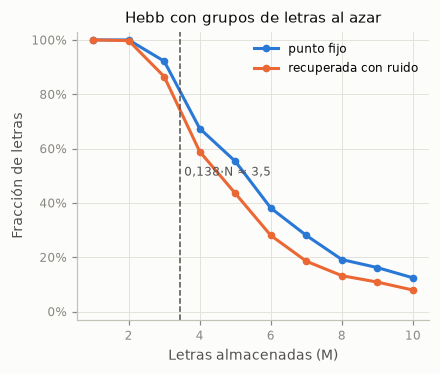

In [4]:
N_LETTERS = 25
cap = letters.capacity(range(1, 11), n_groups=200, noise_fraction=0.12, seed=0)
cap_summary = cap.groupby("M").mean()
display(cap_summary.T)
plots.plot_rates({"Hebb con grupos de letras al azar": cap_summary}, xlabel="Letras almacenadas (M)",
                 ylabel="Fracción de letras", vline=(0.138 * N_LETTERS, "0,138·N ≈ 3,5"),
                 x_percent=False)
plt.show()

In [5]:
for name, group in {"Elegido": GROUP, "Ejemplo inicial": DRAFT_GROUP, "Menos ortogonal": WORST_GROUP}.items():
    model = Hopfield().fit(letters.stack(group))
    print(f"{name:<16} {', '.join(group)}: neuronas estables por letra {model.stable_fraction().round(2)}")

Elegido          G, R, T, V: neuronas estables por letra [1. 1. 1. 1.]
Ejemplo inicial  J, O, X, L: neuronas estables por letra [1. 1. 1. 1.]
Menos ortogonal  H, M, N, W: neuronas estables por letra [0.92 0.92 1.   0.92]


- Con letras al azar, la capacidad cae justo donde predice la teoría: con 3 letras el 92 % queda como punto fijo, con **4 letras sólo el 67 %** y con 5, el 55 %. Desde una copia con ruido, se recuperan el 86 %, 59 % y 43 %.
- **Cuatro letras ya superan $0.138\,N$.** Que funcione depende de cuáles se elijan. Con G, R, T, V las 25 neuronas de cada letra son estables. Con H, M, N, W, tres de las cuatro letras tienen 2 neuronas (8 %) con el signo invertido por el ruido cruzado, así que ni siquiera la letra exacta es un punto fijo.
- La ortogonalidad es la que define la capacidad práctica: el límite teórico supone patrones sin correlación, y las letras reales están lejos de eso.

## 4. Recuperación con ruido

Cada letra se consulta 100 veces con una fracción de píxeles invertidos al azar. El resultado puede ser la letra correcta, un estado espurio, otra letra almacenada o el inverso de alguna.

nivel,0.04,0.08,0.12,0.16,0.20,0.24,0.28,0.32,0.40,0.48
col_0,,,,,,,,,,
letra correcta,1.00,1.00,0.99,0.95,0.90,0.76,0.66,0.45,0.15,0.02
estado espurio,0.00,0.00,0.01,0.05,0.10,0.21,0.30,0.40,0.45,0.29
otra letra o inverso,0.00,0.00,0.00,0.00,0.00,0.03,0.04,0.16,0.40,0.69


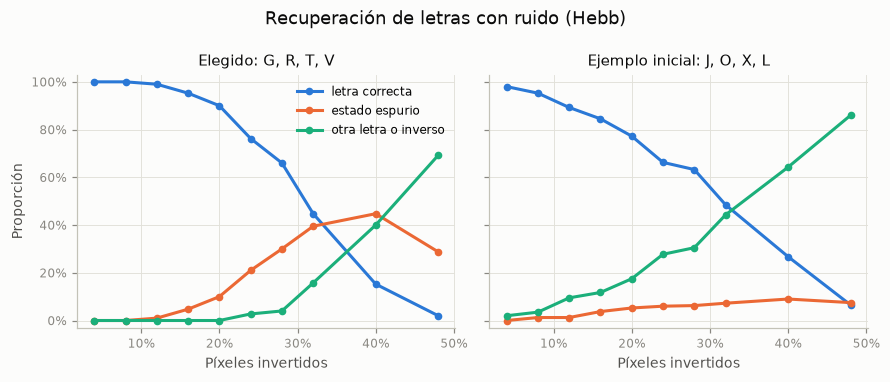

In [6]:
LEVELS = [0.04, 0.08, 0.12, 0.16, 0.20, 0.24, 0.28, 0.32, 0.40, 0.48]


def outcome_rates(table):
    kind = np.select(
        [table["correcto"], table["resultado"] == "espurio"],
        ["letra correcta", "estado espurio"],
        "otra letra o inverso",
    )
    rates = pd.crosstab(table["nivel"], kind, normalize="index")
    return rates.reindex(columns=["letra correcta", "estado espurio", "otra letra o inverso"], fill_value=0)


rates = {}
for name, group in {"Elegido": GROUP, "Ejemplo inicial": DRAFT_GROUP}.items():
    model = Hopfield().fit(letters.stack(group))
    images = {c: letters.LETTERS[c] for c in group}
    table = recovery(model, images, noise.flip, LEVELS, trials=100, seed=1)
    rates[f"{name}: {', '.join(group)}"] = outcome_rates(table)
plots.plot_rates(rates, xlabel="Píxeles invertidos", suptitle="Recuperación de letras con ruido (Hebb)")
display(rates[f"Elegido: {', '.join(GROUP)}"].T)

- Con **G, R, T, V** la recuperación es perfecta hasta 8 % de ruido (2 píxeles), del 99 % con 12 % y del 90 % con 20 %. Desde ahí, los errores son sobre todo **estados espurios**, que llegan al 45 % con 40 % de ruido.
- Con **J, O, X, L** ya hay errores con 4 % de ruido, y fallan casi siempre hacia **otra letra o un inverso**: como la O se parece a $-$X, una O con ruido cae fácilmente en el inverso de la X.
- Con 48 % de ruido la consulta ya no tiene información sobre la letra de origen: termina en cualquier atractor (otra letra, un inverso o un espurio).

## 5. Estados espurios

Con $N = 25$ se pueden recorrer los $2^{25} \approx 33$ millones de estados y encontrar **todos** los puntos fijos de la red.

In [7]:
model = Hopfield().fit(letters.stack(GROUP))
P = letters.stack(GROUP)
points = fixed_points(model)
kinds = pd.Series([identify(p, P, GROUP) for p in points])
kinds = kinds.where(kinds == "espurio", np.where(kinds.str.startswith("inverso"), "inverso", "almacenado"))
spurious = points[(kinds == "espurio").to_numpy()]
is_mixture = np.array([mixture(s, P, GROUP) is not None for s in spurious])
energies = pd.DataFrame({"tipo": kinds, "energía": [model.energy(p) for p in points]})
print(f"Puntos fijos entre los 2^25 estados: {len(points)}")
print(f"Espurios que son mezcla de 3 letras: {is_mixture.sum()} de {len(spurious)}")
display(energies.groupby("tipo")["energía"].agg(["count", "min", "max"]))

starts = np.random.default_rng(0).choice([-1.0, 1.0], size=(2000, 25))
landing = pd.Series([identify(model.recall(s, seed=i).state, P, GROUP) for i, s in enumerate(starts)])
landing = landing.where(landing == "espurio", np.where(landing.str.startswith("inverso"), "inverso", "almacenado"))
print("Destino desde 2000 estados al azar:")
display(landing.value_counts(normalize=True))

Puntos fijos entre los 2^25 estados: 64
Espurios que son mezcla de 3 letras: 28 de 56


,count,min,max
tipo,,,
almacenado,4,-10.72,-10.56
espurio,56,-8.80,-6.72
inverso,4,-10.72,-10.56


Destino desde 2000 estados al azar:


espurio      0.35
inverso      0.33
almacenado   0.32
Name: proportion, dtype: float64

La red tiene **64 puntos fijos**: las 4 letras, sus 4 inversos y **56 estados espurios**. La mitad (28) son **mezclas** de tres letras, $\operatorname{sign}(\pm\xi^a \pm \xi^b \pm \xi^c)$, el espurio típico de Hebb. Todos los espurios tienen más energía (entre $-8.8$ y $-6.7$) que las letras (entre $-10.7$ y $-10.6$): son mínimos más **superficiales**. Aun así, desde un estado al azar la red cae en un espurio el 35 % de las veces, porque son muchos.

Para mostrar uno, se consulta la G con 40 % de ruido hasta que el resultado sea un espurio, algo que pasa en ~45 % de las consultas con ese ruido (sección 4):

Consulta: G con 40 % de ruido -> espurio
Mezcla: sign(+G +R −V)
Solapamiento con cada letra: {'G': 0.52, 'R': 0.52, 'T': -0.2, 'V': -0.52}
Pasadas: 2 | neuronas que cambiaron: 8
Energía: -0.16 -> -8.64 (letras almacenadas: -10.72)


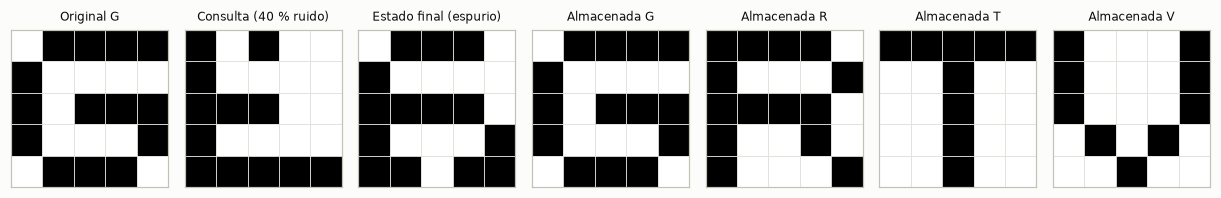

In [8]:
# Patrón muy ruidoso: 40 % de los píxeles de una letra invertidos.
rng = np.random.default_rng(3)
source = GROUP[0]
for attempt in range(200):
    noisy = noise.flip(letters.LETTERS[source], 0.40, rng)
    result = model.recall(noisy, seed=attempt)
    if identify(result.state, P, GROUP) == "espurio" and mixture(result.state, P, GROUP):
        break
print(f"Consulta: {source} con 40 % de ruido -> {identify(result.state, P, GROUP)}")
print(f"Mezcla: sign({mixture(result.state, P, GROUP)})")
print(f"Solapamiento con cada letra: {dict(zip(GROUP, (P @ result.state.ravel() / 25).round(2).tolist()))}")
print(f"Pasadas: {result.sweeps} | neuronas que cambiaron: {len(result.energy) - 1}")
print(f"Energía: {result.energy[0]:.2f} -> {result.energy[-1]:.2f} "
      f"(letras almacenadas: {model.energy(P[0]):.2f})")
plots.plot_patterns(
    [letters.LETTERS[source], noisy, result.state] + [letters.LETTERS[c] for c in GROUP],
    [f"Original {source}", "Consulta (40 % ruido)", "Estado final (espurio)"]
    + [f"Almacenada {c}" for c in GROUP],
    ncols=7, size=1.6,
)
plt.show()

La consulta (10 píxeles invertidos) converge en 2 pasadas a un estado que **no es ninguna letra**. Es exactamente $\operatorname{sign}(\xi^G + \xi^R - \xi^V)$: se parece por igual a G y a R (solapamiento 0.52, es decir, difiere en 6 píxeles de cada una) y al inverso de V. Es un híbrido que no es ninguna de las dos letras. La energía baja de $-0.16$ a $-8.64$ y se detiene en un mínimo local más alto que el de las letras ($-10.72$). La red no tiene forma de "saber" que se equivocó: un espurio es un punto fijo como cualquier otro.

## 6. Los códigos QR como patrones

**El problema.** La Trattoria Aurora tiene cinco cartas digitales (menú principal, vinos, cócteles y bebidas, postres y especiales del día), cada una con su QR impreso en las mesas. Con el uso, los códigos se rompen, se manchan y se rayan, y dejan de poder escanearse. La propuesta es guardar los cinco QR en una red de Hopfield, pasarle el código deteriorado y entregar el patrón recuperado a un lector de QR.

**Criterio de éxito:** que un lector real (`zxing-cpp`) abra el menú correcto a partir del QR recuperado.

Los cinco QR ya vienen en 37×37 (QR versión 5, un píxel por módulo) en blanco y negro puro, así que la binarización con umbral 128 no pierde información: $N = 1369$ neuronas. Para verificar todo el flujo se leen los originales con un lector real (`zxing-cpp`), agregando el margen blanco de 4 módulos que exige el estándar.

,lectura,corrección de errores,fracción negra
Menú principal,food_menu.png,L,0.52
Vinos,wine_menu.png,L,0.52
Cócteles y bebidas,beverages_menu.png,L,0.52
Postres,dessert_menu.png,L,0.53
Especiales del día,specials_menu.png,L,0.51


Prefijo común de las URL: https://github.com/eugepineiro/sia-tips/blob/feature/tp4-images/TPs/TP4/


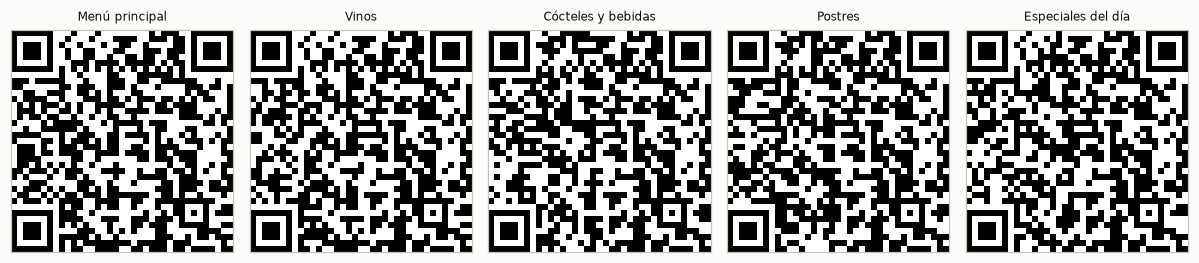

In [9]:
codes = qr.load_codes()
MENU_NAMES = list(codes)
Q = np.array([c.ravel() for c in codes.values()])
URLS = {name: qr.decode(code) for name, code in codes.items()}
display(pd.DataFrame({
    "lectura": [url.rsplit("/", 1)[-1] for url in URLS.values()],
    "corrección de errores": [qr.error_correction_level(c) for c in codes.values()],
    "fracción negra": [(c > 0).mean() for c in codes.values()],
}, index=MENU_NAMES))
print(f"Prefijo común de las URL: {URLS[MENU_NAMES[0]].rsplit('/', 1)[0]}/")
plots.plot_patterns(list(codes.values()), MENU_NAMES, ncols=5, size=2.2)
plt.show()

Píxeles iguales en los 5 códigos: 70%


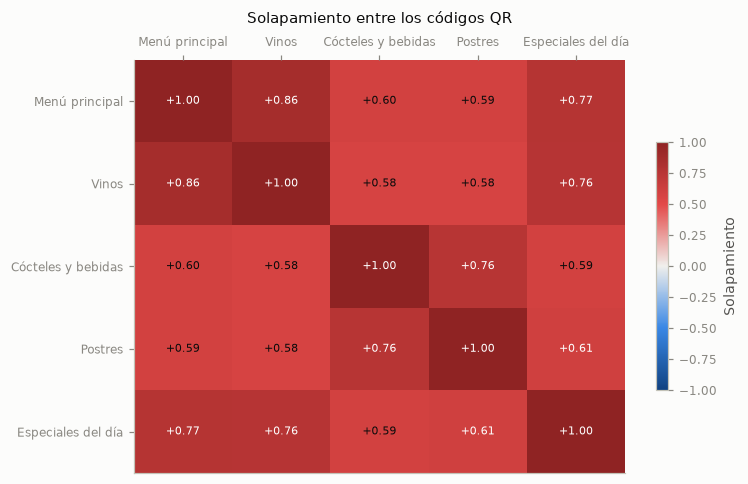

In [10]:
O = pd.DataFrame(overlaps(Q), index=MENU_NAMES, columns=MENU_NAMES)
plots.plot_annotated_heatmap(O, "Solapamiento entre los códigos QR", "Solapamiento", limit=1, figsize=(7, 4.5))
common = np.mean(np.all(Q == Q[0], axis=0))
print(f"Píxeles iguales en los 5 códigos: {common:.0%}")

- Los cinco códigos se leen bien y usan corrección de errores **nivel L**, la más baja del estándar: recupera hasta ~7 % de los datos. Por eso un QR real deja de leerse con muy poco daño.
- Los códigos están **muy correlacionados** (solapamiento entre 0.58 y 0.86) y el **70 % de los píxeles es igual en los cinco**. Comparten las tres marcas de posición, las líneas de sincronismo y la información de formato. Además, las cinco URL tienen el mismo prefijo de 72 caracteres, así que también coincide gran parte de los datos. Lo que distingue a cada menú es una minoría de píxeles.

## 7. Hebb falla: regla de la pseudoinversa

In [11]:
N_QR = Q.shape[1]
qr_models = {rule: Hopfield(rule).fit(Q) for rule in ("hebb", "pseudoinversa")}
rows = []
for rule, m in qr_models.items():
    for name, image, stable in zip(MENU_NAMES, codes.values(), m.stable_fraction()):
        result = m.recall(image)
        rows.append({"regla": rule, "menú": name, "neuronas estables": stable,
                     "resultado": identify(result.state, Q, MENU_NAMES),
                     "píxeles distintos": int((result.state != image).sum()),
                     "se lee": qr.decode(result.state) == URLS[name]})
display(pd.DataFrame(rows).set_index(["regla", "menú"]))
print(f"Capacidad teórica de Hebb con patrones al azar: 0,138·N = {0.138 * N_QR:.0f} patrones")

hebb_end = qr_models["hebb"].recall(codes[MENU_NAMES[0]]).state
print("Solapamiento del estado final de Hebb con cada menú:",
      dict(zip(MENU_NAMES, (Q @ hebb_end.ravel() / N_QR).round(2).tolist())))

neuronas estables           resultado  \
regla         menú                                                        
hebb          Menú principal                   0.95             espurio   
              Vinos                            0.93             espurio   
              Cócteles y bebidas               0.84             espurio   
              Postres                          0.84             espurio   
              Especiales del día               0.92             espurio   
pseudoinversa Menú principal                   1.00      Menú principal   
              Vinos                            1.00               Vinos   
              Cócteles y bebidas               1.00  Cócteles y bebidas   
              Postres                          1.00             Postres   
              Especiales del día               1.00  Especiales del día   

                                  píxeles distintos  se lee  
regla         menú                                           
hebb          Menú principal                     71   False  
              Vinos                              91   False  
              Cócteles y bebidas                225   False  
              Postres                           225   False  
              Especiales del día                103   False  
pseudoinversa Menú principal                      0    True  
              Vinos                               0    True  
              Cócteles y bebidas                  0    True  
              Postres                             0    True  
              Especiales del día                  0    True

Capacidad teórica de Hebb con patrones al azar: 0,138·N = 189 patrones
Solapamiento del estado final de Hebb con cada menú: {'Menú principal': 0.9, 'Vinos': 0.87, 'Cócteles y bebidas': 0.67, 'Postres': 0.67, 'Especiales del día': 0.85}


**Con Hebb, ni siquiera el QR original es un punto fijo.** Según la capacidad teórica ($0.138 \cdot 1369 \approx 189$ patrones), 5 deberían caber de sobra. Pero esa cota supone patrones sin correlación, y acá el ruido cruzado de los otros cuatro códigos (solapamientos de 0.58 a 0.86) invierte entre el 5 % y el 16 % de las neuronas. Los cinco originales terminan en **el mismo estado espurio**, una mezcla que se parece a todos (0.90 con Menú principal, 0.87 con Vinos) y que el lector no puede leer.

La **regla de la pseudoinversa** (sección 1) resuelve el problema, porque el solapamiento entre patrones deja de producir ruido cruzado. Los cinco quedan como puntos fijos y se leen correctamente. Sigue siendo una red de Hopfield: pesos simétricos, diagonal nula y la misma dinámica y energía. A partir de acá se usa esta regla.

## 8. Deterioro de los códigos y lectura

Se simulan cuatro deterioros (`noise.py`), con 10 consultas por menú y nivel:

| Deterioro | Simulación |
|---|---|
| Ruido aleatorio | invierte una fracción de píxeles al azar (desgaste uniforme) |
| Esquina rota | triángulo blanco en una esquina al azar |
| Mancha | disco negro en una posición al azar (comida) |
| Rayones | segmentos blancos al azar |

En los tres daños con forma, el nivel es el área cubierta. Sólo cambian los píxeles que tenían el color contrario (cerca de la mitad), así que el eje x muestra la fracción de píxeles realmente cambiados. Se compara si el lector lee el QR **dañado** directamente y si lee el QR **recuperado por la red**.

¿La lectura con red coincide siempre con recuperar el menú exacto? True


Lector solo  Hopfield + lector  \
daño            píxeles cambiados                                   
Ruido aleatorio 0.05                      0.00               1.00   
                0.10                      0.00               1.00   
                0.20                      0.00               1.00   
                0.30                      0.00               1.00   
                0.40                      0.00               0.98   
                0.45                      0.00               0.66   
                0.50                      0.00               0.00   
Esquina rota    0.03                      0.30               1.00   
                0.05                      0.00               1.00   
                0.11                      0.00               1.00   
                0.15                      0.00               1.00   
                0.21                      0.00               1.00   
                0.27                      0.00               0.86   
                0.31                      0.00               0.96   
Mancha          0.02                      0.78               1.00   
                0.05                      0.00               1.00   
                0.10                      0.00               1.00   
                0.15                      0.00               1.00   
                0.19                      0.00               0.98   
                0.24                      0.00               1.00   
                0.29                      0.00               1.00   
Rayones         0.03                      0.00               1.00   
                0.06                      0.00               1.00   
                0.11                      0.00               1.00   
                0.16                      0.00               1.00   
                0.21                      0.00               1.00   
                0.26                      0.00               1.00   
                0.31                      0.00               1.00   

                                   Hopfield: otro menú  
daño            píxeles cambiados                       
Ruido aleatorio 0.05                              0.00  
                0.10                              0.00  
                0.20                              0.00  
                0.30                              0.00  
                0.40                              0.00  
                0.45                              0.10  
                0.50                              0.44  
Esquina rota    0.03                              0.00  
                0.05                              0.00  
                0.11                              0.00  
                0.15                              0.00  
                0.21                              0.00  
                0.27                              0.04  
                0.31                              0.02  
Mancha          0.02                              0.00  
                0.05                              0.00  
                0.10                              0.00  
                0.15                              0.00  
                0.19                              0.02  
                0.24                              0.00  
                0.29                              0.00  
Rayones         0.03                              0.00  
                0.06                              0.00  
                0.11                              0.00  
                0.16                              0.00  
                0.21                              0.00  
                0.26                              0.00  
                0.31                              0.00

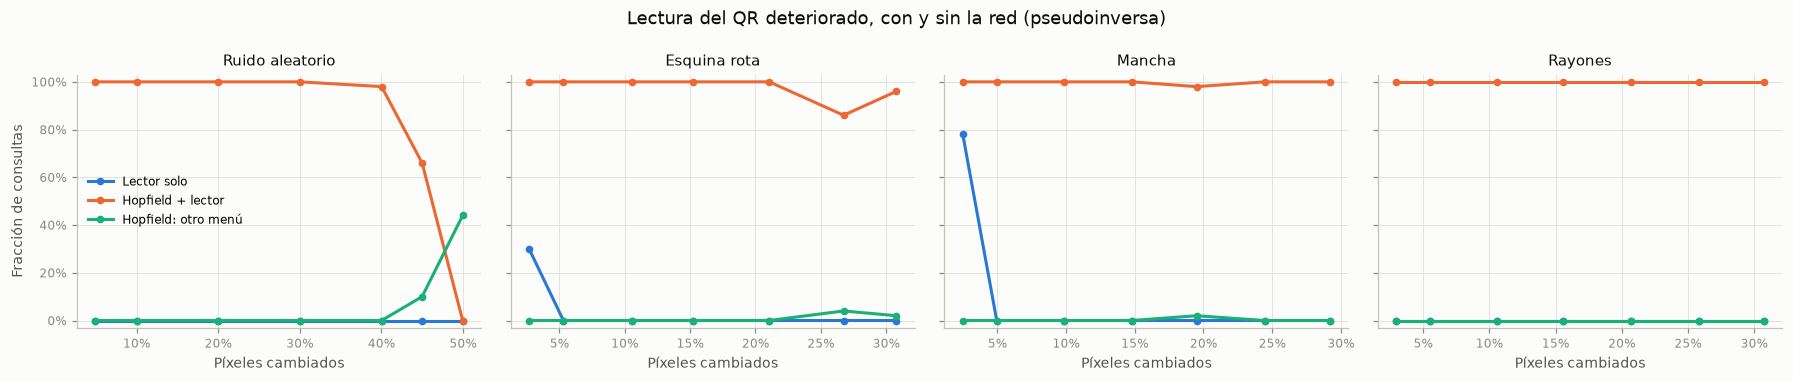

In [12]:
model_qr = qr_models["pseudoinversa"]
QR_LEVELS = {
    "Ruido aleatorio": [0.05, 0.10, 0.20, 0.30, 0.40, 0.45, 0.50],
    "Esquina rota": [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60],
    "Mancha": [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60],
    "Rayones": [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60],
}
damage_tables = {
    damage: recovery(model_qr, codes, noise.DAMAGES[damage], levels, trials=10,
                     decoder=qr.decode, seed=4)
    for damage, levels in QR_LEVELS.items()
}


def reading_rates(table):
    table = table.assign(**{"otro menú": table["resultado"].isin(MENU_NAMES) & ~table["correcto"]})
    rates = table.groupby("nivel")[["píxeles cambiados", "lectura sin red", "lectura con red",
                                     "otro menú"]].mean()
    return rates.set_index("píxeles cambiados").rename(columns={
        "lectura sin red": "Lector solo", "lectura con red": "Hopfield + lector",
        "otro menú": "Hopfield: otro menú"})


qr_rates = {damage: reading_rates(table) for damage, table in damage_tables.items()}
plots.plot_rates({d: r[["Lector solo", "Hopfield + lector", "Hopfield: otro menú"]] for d, r in qr_rates.items()},
                 xlabel="Píxeles cambiados", ylabel="Fracción de consultas",
                 suptitle="Lectura del QR deteriorado, con y sin la red (pseudoinversa)")
all_tables = pd.concat(damage_tables)
print("¿La lectura con red coincide siempre con recuperar el menú exacto?",
      bool((all_tables["lectura con red"] == all_tables["correcto"]).all()))
display(pd.concat(qr_rates, names=["daño"]))

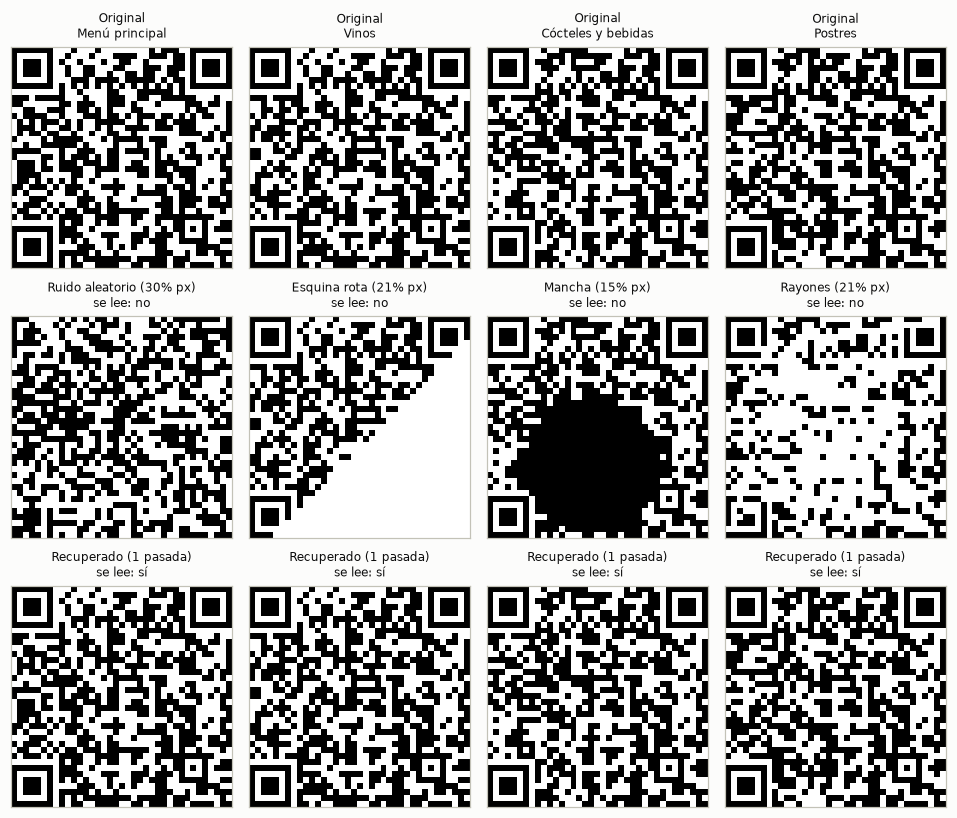

In [13]:
# Una columna por caso, leída de arriba hacia abajo: original, dañado y recuperado.
rng = np.random.default_rng(7)
CASES = [("Ruido aleatorio", 0.30), ("Esquina rota", 0.40), ("Mancha", 0.30), ("Rayones", 0.40)]
originals, damaged_row, recovered_row = [], [], []
for (damage, level), name in zip(CASES, MENU_NAMES):
    damaged = noise.DAMAGES[damage](codes[name], level, rng)
    result = model_qr.recall(damaged)
    originals.append((codes[name], f"Original\n{name}"))
    damaged_row.append((damaged, f"{damage} ({np.mean(damaged != codes[name]):.0%} px)\n"
                                 f"se lee: {'sí' if qr.decode(damaged) else 'no'}"))
    recovered_row.append((result.state, f"Recuperado ({result.sweeps} pasada{'s' if result.sweeps != 1 else ''})\n"
                                        f"se lee: {'sí' if qr.decode(result.state) == URLS[name] else 'no'}"))
images, titles = zip(*(originals + damaged_row + recovered_row))
plots.plot_patterns(images, titles, ncols=len(CASES), size=2.2)
plt.show()

- **El lector solo casi no tolera daño.** Sólo lee algunos códigos con 2–3 % de píxeles cambiados (78 % de las manchas chicas, 30 % de las esquinas chicas) y ninguno desde el 5 %. Es lo esperable con corrección nivel L.
- **Con la red antes del lector**, se leen el 100 % de los códigos con hasta 30 % de ruido aleatorio y el 98 % con 40 %. Con daños realistas, se leen el 100 % de los rayones hasta 31 % de píxeles cambiados, ≥ 98 % de las manchas hasta 29 % y el 100 % de las esquinas rotas hasta 21 % (86–96 % por encima).
- Cuando la red recupera el menú exacto, el lector siempre lo lee: el QR recuperado es idéntico al original.
- **El modo de falla puede ser silencioso.** Con 45 % de ruido aleatorio la red recupera el 66 %. Cuando falla, suele terminar en un espurio o un inverso, que el lector no lee; pero en el 10 % de las consultas devuelve **otro menú** (línea `Hopfield: otro menú` del gráfico), y el lector abre una carta equivocada sin señal de error. Con 50 % la consulta ya no tiene información y otro menú es el resultado del 44 % de las consultas.

## 9. Iteraciones y energía

In [14]:
sweeps = all_tables.reset_index(level=0).rename(columns={"level_0": "daño"})
display(sweeps.groupby(["daño", "nivel"])[["pasadas", "cambios"]].mean().unstack(0).round(1))

pasadas                                     cambios                 \
daño  Esquina rota Mancha Rayones Ruido aleatorio Esquina rota Mancha Rayones   
nivel                                                                           
0.05          1.00   1.00    1.00            1.00        36.80  34.00   40.90   
0.10          1.00   1.00    1.00            1.00        72.70  67.80   75.70   
0.20          1.00   1.00    1.00            1.00       144.80 134.60  144.50   
0.30          1.00   1.00    1.00            1.00       208.90 202.70  213.30   
0.40          1.10   1.10    1.00            1.20       288.90 267.60  283.70   
0.45           NaN    NaN     NaN            1.60          NaN    NaN     NaN   
0.50          1.10   1.10    1.00            1.90       366.90 335.20  353.60   
0.60          1.30   1.10    1.00             NaN       424.20 400.80  420.50   

                       
daño  Ruido aleatorio  
nivel                  
0.05            68.00  
0.10           137.00  
0.20           274.00  
0.30           411.00  
0.40           549.60  
0.45           622.60  
0.50           677.00  
0.60              NaN

10% de ruido → Menú principal: -436 -> -682 en 137 cambios
30% de ruido → Menú principal: -109 -> -682 en 411 cambios
45% de ruido → Menú principal: -9 -> -682 en 622 cambios
Energía de los menús almacenados: -682.0 | energía media de un estado al azar: -0.1


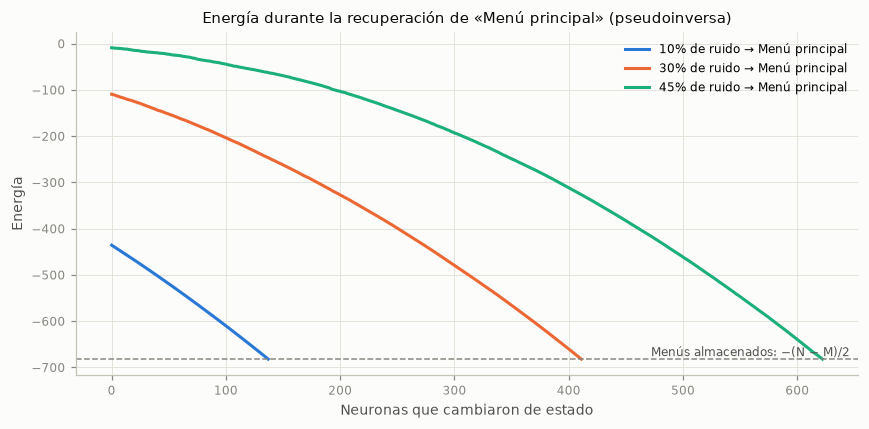

In [15]:
rng = np.random.default_rng(11)
name = MENU_NAMES[0]
curves = {}
for level in (0.10, 0.30, 0.45):
    result = model_qr.recall(noise.flip(codes[name], level, rng), seed=1)
    curves[f"{level:.0%} de ruido → {identify(result.state, Q, MENU_NAMES)}"] = result.energy
references = {"Menús almacenados: −(N − M)/2": model_qr.energy(codes[name])}
plots.plot_energy(curves, references, f"Energía durante la recuperación de «{name}» (pseudoinversa)")
for label, energy in curves.items():
    print(f"{label}: {energy[0]:.0f} -> {energy[-1]:.0f} en {len(energy) - 1} cambios")
print(f"Energía de los menús almacenados: {model_qr.energy(codes[name]):.1f} | "
      f"energía media de un estado al azar: "
      f"{np.mean([model_qr.energy(s) for s in rng.choice([-1.0, 1.0], (200, N_QR))]):.1f}")

- **Iteraciones.** Se cuenta como pasada un recorrido completo sobre las 1369 neuronas en el que al menos una cambia. Hasta 30–40 % de daño, la red converge en **una sola pasada**, y el número de neuronas que cambian coincide con el de píxeles dañados (137 con 10 % de ruido, 411 con 30 %): corrige cada píxel dañado una vez y no toca ningún otro. Cerca del 50 % de ruido o con esquinas grandes aparecen pasadas extra (hasta 1.9 en promedio), porque los primeros cambios se hacen hacia un patrón equivocado y después se corrigen.
- **Energía.** Baja de forma monótona en cada cambio, como garantiza la dinámica asincrónica, desde un valor que depende del daño ($-436$ con 10 % de ruido, $-9$ con 45 %, $\approx 0$ en un estado al azar) hasta $-682$. Con la pseudoinversa, todos los menús almacenados tienen la **misma** energía, $-\tfrac12(N - M) = -\tfrac12(1369 - 5) = -682$. Por eso la energía final no distingue un menú de otro: llegar a $-682$ indica que la red cayó en *algún* menú, no en cuál. Las curvas se aceleran hacia el final porque cada corrección aumenta el campo $|h_i|$ de las neuronas que faltan corregir.

## 10. Limitaciones del caso de uso

In [16]:
import zxingcpp

new_url = "https://github.com/eugepineiro/sia-tips/blob/feature/tp4-images/TPs/TP4/brunch_menu.png"
new_code = qr.to_pattern(np.array(
    zxingcpp.create_barcode(new_url, zxingcpp.BarcodeFormat.QRCode, ec_level="L")
    .to_image(scale=1, add_quiet_zones=False)))
new_result = model_qr.recall(new_code)
print(f"QR nuevo ({new_code.shape[0]}×{new_code.shape[1]}), sin daño: {qr.decode(new_code).rsplit('/', 1)[-1]}")
print(f"  solapamiento con los almacenados: {(Q @ new_code.ravel() / N_QR).round(2)}")
print(f"  la red devuelve: {identify(new_result.state, Q, MENU_NAMES)} -> "
      f"el lector abre {qr.decode(new_result.state).rsplit('/', 1)[-1]}")

shifted_rows = []
for name, image in codes.items():
    for shift in [(0, 1), (1, 0), (1, 1)]:
        moved = np.roll(image, shift, axis=(0, 1))
        shifted_rows.append({"menú": name, "corrimiento (filas, columnas)": str(shift),
                             "píxeles cambiados": np.mean(moved != image),
                             "resultado": identify(model_qr.recall(moved).state, Q, MENU_NAMES)})
shifted = pd.DataFrame(shifted_rows)
shifted["menú correcto"] = shifted["resultado"] == shifted["menú"]
display(shifted.groupby("corrimiento (filas, columnas)")[["píxeles cambiados", "menú correcto"]].mean())

QR nuevo (37×37), sin daño: brunch_menu.png
  solapamiento con los almacenados: [0.21 0.21 0.17 0.18 0.2 ]
  la red devuelve: Menú principal -> el lector abre food_menu.png


,píxeles cambiados,menú correcto
"corrimiento (filas, columnas)",,
"(0, 1)",0.47,0.20
"(1, 0)",0.47,0.00
"(1, 1)",0.53,0.00


- **Sólo conoce los 5 menús guardados y siempre responde con uno.** Un QR nuevo y sano (un supuesto "menú brunch") termina en *Menú principal*, y el lector abre esa carta. La red no puede decir "no lo reconozco". En producción haría falta un umbral de confianza, por ejemplo el solapamiento de la consulta con el menú recuperado o la cantidad de píxeles corregidos.
- **Agregar o cambiar un menú obliga a recalcular $W$**, y el sistema deja de servir si un menú cambia de URL. La pseudoinversa tampoco se puede actualizar sumando un término como Hebb. La capacidad no es el problema ($M \le N = 1369$); lo es el mantenimiento.
- **No tolera desplazamientos, rotaciones ni cambios de escala.** Correr el código un solo píxel cambia ~50 % de los píxeles y la red falla. Con una foto real habría que detectar el código, corregir la perspectiva, recortarlo, llevarlo a 37×37 y binarizarlo *antes* de la red, y esos pasos son justamente los que un lector de QR ya resuelve.
- **Costo y tamaño fijo.** La red sólo acepta códigos de 37×37 y tiene $N^2 \approx 1.9$ millones de pesos. Un QR más grande (versión 10, 57×57) tendría 3249 neuronas y ~10 millones de pesos. Con Hebb, que es la regla clásica, la red ni siquiera funciona por la correlación entre códigos.
- **Con sólo 5 patrones posibles, la red equivale a buscar el menú más parecido.** Comparar la consulta con los 5 originales daría el mismo resultado con 5 × 1369 operaciones. Y la solución más simple para el restaurante es imprimir los QR con corrección **nivel H** (~30 % de daño tolerable) o plastificarlos. El valor de la red está en mostrar la memoria asociativa: completar un patrón a partir de una parte, con la energía como garantía de convergencia.

## 11. Conclusiones

- **Respuesta al objetivo:** una red de Hopfield puede recuperar información a partir de patrones incompletos o ruidosos. Con los QR, convierte códigos que el lector no lee (desde ~3–5 % de daño) en códigos legibles con hasta 30–40 % de daño, siempre que los patrones estén bien almacenados.
- **La ortogonalidad define la capacidad práctica.** Con 25 neuronas, 4 letras ya están por encima de $0.138\,N$, y sólo funcionan si se eligen poco solapadas (G, R, T, V: solapamiento ≤ 0.12). Con letras parecidas, ni el patrón exacto es estable.
- **Los estados espurios son inevitables con Hebb.** La red de 4 letras tiene 56 espurios, la mitad mezclas de tres letras. Una consulta muy ruidosa (40 %) termina en uno, $\operatorname{sign}(G + R - V)$, que es un mínimo de energía más alto que las letras pero del que la red no sale.
- **Con los QR, Hebb falla del todo** porque los códigos comparten el 70 % de los píxeles. La **pseudoinversa** los guarda sin errores y convierte un QR ilegible (el lector solo falla desde ~3–5 % de daño) en uno legible con hasta 30–40 % de ruido o daños localizados. Converge en una pasada, corrige exactamente los píxeles dañados y la energía baja de forma monótona hasta $-(N-M)/2$.
- **Como sistema real tiene límites claros:** siempre devuelve uno de los menús conocidos (incluso ante un QR que no conoce), no tolera desplazamientos y hay que rehacerla cada vez que cambia un menú.